In [1]:
import re
import numpy as np
import pandas as pd
from qiskit_metal import designs, Dict
from qiskit_metal.qlibrary.qubits.transmon_pocket import TransmonPocket
from qiskit_metal.analyses.quantization import LOManalysis

design = designs.DesignPlanar({}, overwrite_enabled=True)
design.overwrite_enabled = True
design.delete_all_components()

# NET ORDER MATTERS: LOManalysis expects the Q3D capacitance matrix ordered
#   [bus_1 ... bus_N-1, ground, pad_bot, pad_top, readout]   (= alphabetical net names)
# so name the bus pins so they sort BEFORE "ground" and the readout pin AFTER "pad_top".
Q            = "Q0"
BUS_PINS     = ["to_Q2", "to_Q4"]     # keep alphabetical; order here = order of lom.setup.freq_bus
READOUT_PIN  = "readout"

pad_opts = Dict(pad_width="50um", pad_height="30um", pad_gap="30um")    # connection-pad geometry

q0 = TransmonPocket(design, 'Q0', options=Dict(
    pos_x='0 um', pos_y='0 um', orientation=90, pad_width='500 um', pad_height= "120 um", pad_gap = '30 um',
    pocket_width = '800 um', pocket_height = '800 um',
    connection_pads=Dict(
        to_Q4  =Dict(loc_W=-1, loc_H=-1, **pad_opts),
        to_Q2  =Dict(loc_W=-1, loc_H=+1, **pad_opts),
        readout=Dict(loc_W=+1, loc_H=+1, **pad_opts),
    )))

design.rebuild()

In [15]:
design.chips

{'main': {'material': 'silicon',
  'layer_start': '0',
  'layer_end': '2048',
  'size': {'center_x': '0.0mm',
   'center_y': '0.0mm',
   'center_z': '0.0mm',
   'size_x': '9mm',
   'size_y': '6mm',
   'size_z': '-750um',
   'sample_holder_top': '890um',
   'sample_holder_bottom': '1650um'}}}

In [2]:
# ------------------------------------------------------------------ LOManalysis (Q3D) setup
lom = LOManalysis(design, "q3d")
lom.sim.setup.freq_ghz = 5.0                 # Q3D solution frequency [GHz]
lom.setup.junctions    = Dict(Lj=12, Cj=2)   # nH, fF
lom.setup.freq_readout = 7.0                 # GHz
lom.setup.freq_bus     = [6.0, 6.2]          # GHz, same order as BUS_PINS


# ------------------------------------------------------------------ helpers (bookkeeping only)
import io
from contextlib import redirect_stdout, nullcontext
def _set_opt(design, qcomp, key, value):
    design.components[qcomp].options[key] = value

def _geometry_um(design, qcomp, pins):
    """Qubit-pad and every connection-pad width/height/gap in um (parsed options are in mm)."""
    p = design.components[qcomp].p
    g = {f"{k}_um": p[k] * 1e3 for k in ("pad_width", "pad_height", "pad_gap")}
    for pin in pins:
        for k in ("pad_width", "pad_height", "pad_gap"):
            g[f"{pin}_{k}_um"] = p.connection_pads[pin][k] * 1e3
    return g

def _net_labels(cmat, qcomp, bus_pins, readout_pin):
    """Label the LOM per-pad outputs from the REAL Q3D net order; flag if it is not the order LOM assumes."""
    nets, n = list(cmat.index), len(bus_pins)
    pin = lambda s: re.sub(rf"_connector_pad_{re.escape(qcomp)}$", "", s)
    ok = (len(nets) == n + 4
          and all(nets[i].startswith(b + "_connector_pad") for i, b in enumerate(bus_pins))
          and "ground" in nets[n].lower()
          and nets[n + 1].startswith("pad_bot") and nets[n + 2].startswith("pad_top")
          and nets[-1].startswith(readout_pin + "_connector_pad"))
    labels = [pin(nets[-1])] + [pin(x) for x in nets[:n]]      # LOM output order: [readout, bus1, bus2, ...]
    return labels, ok

def _flatten(d, labels):
    """lumped_oscillator dict -> flat {key: float}; per-pad arrays become key_<pin>."""
    out = {}
    for k, v in d.items():
        a = np.asarray(v, dtype=float)
        if a.ndim == 0:
            out[k] = float(a)
        else:
            out.update({f"{k}_{lab}": float(x) for lab, x in zip(labels, a.ravel())})
    return out


# ------------------------------------------------------------------ 2-D sweep: Sweeper (pad_width) inside a loop (pad_height)
def sweep_lom_2d(design, lom, qcomp, bus_pins, readout_pin, width_values, height_values, quiet=True):
    """Sweep qubit pad_width x pad_height with qiskit-metal's Sweeper (LOManalysis.run_sweep -> Q3D -> run_lom).
    Returns (df, raw): one DataFrame row per (width, height); raw holds each point's cap matrix and per-pass LOM."""
    pins       = [*bus_pins, readout_pin]
    open_terms = [(qcomp, p) for p in pins]            # every connection pad is a floating net in Q3D
    s          = lom.setup
    inputs     = {"in_Lj_nH": s.junctions.Lj, "in_Cj_fF": s.junctions.Cj, "in_f_readout_GHz": s.freq_readout,
                  **{f"in_f_{b}_GHz": f for b, f in zip(bus_pins, s.freq_bus)}}

    opts = design.components[qcomp].options
    orig_w, orig_h = opts["pad_width"], opts["pad_height"]

    rows, raw = [], {}
    # Sweeper logs (not raises) a failed run and then re-records the PREVIOUS point's data,
    # so keep every variables-object seen: the same object twice = stale = failed point.
    keep = [lom._variables, lom.sim._variables]
    seen = {id(o) for o in keep}
    try:
        for h in height_values:
            _set_opt(design, qcomp, "pad_height", h)
            with redirect_stdout(io.StringIO()) if quiet else nullcontext():       # quiet: hide run_lom's print_info
                all_sweep, status = lom.run_sweep(qcomp, "pad_width", list(width_values),
                                                  components=[qcomp], open_terminations=open_terms)
            if status != 0:
                raise RuntimeError(f"Sweeper status {status} (1 component not found, 2 empty option, "
                                   f"3 bad option path, 4 empty sweep, 5 leaf key missing)")
            for w, entry in all_sweep.items():
                v, sv = entry["variables"], entry["sim_variables"]
                stale = id(v) in seen or id(sv) in seen
                seen |= {id(v), id(sv)}; keep += [v, sv]
                lo = v.get("lumped_oscillator")

                row = {"pad_width_um": design.parse_value(w) * 1e3, "pad_height_um": design.parse_value(h) * 1e3}
                row.update({k: x for k, x in _geometry_um(design, qcomp, pins).items() if k not in row})
                row.update(inputs)
                labels, net_ok = ("-", "-"), False
                cm = sv.get("cap_matrix")
                if cm is not None and len(cm):
                    labels, net_ok = _net_labels(cm, qcomp, bus_pins, readout_pin)
                if lo is not None and not stale:
                    row.update(_flatten(lo, labels))
                row.update({"is_converged": sv.get("is_converged"), "net_order_ok": net_ok,
                            "ok": lo is not None and not stale})
                rows.append(row)
                if row["ok"]:
                    raw[(row["pad_width_um"], row["pad_height_um"])] = Dict(
                        cap_matrix=cm, cap_units=sv.get("units"), cap_all_passes=sv.get("cap_all_passes"),
                        lumped_oscillator_all=v.get("lumped_oscillator_all"))
    finally:                                           # Sweeper leaves the LAST value in the design: restore
        _set_opt(design, qcomp, "pad_width", orig_w)
        _set_opt(design, qcomp, "pad_height", orig_h)
        design.rebuild()

    df = pd.DataFrame(rows)
    bad = df[~df["ok"]]
    print(f"{len(df) - len(bad)}/{len(df)} points OK"
          + (f" | FAILED (width, height) um: {list(zip(bad.pad_width_um, bad.pad_height_um))}" if len(bad) else ""))
    if not df.loc[df["ok"], "net_order_ok"].all():
        print("WARNING: Q3D net order differs from [bus..., ground, pad_bot, pad_top, readout]; "
              "check cap_matrix.index in `raw` and the pin names before trusting g / chi.")
    return df, raw


# ------------------------------------------------------------------ run
WIDTHS  = ["400um", "450um", "500um", "550um", "600um"]      # strings WITH units
HEIGHTS = ["80um", "100um", "120um"]

df, raw = sweep_lom_2d(design, lom, Q, BUS_PINS, READOUT_PIN, WIDTHS, HEIGHTS)
df

INFO 03:14PM [connect_project]: Connecting to Ansys Desktop API...
INFO 03:14PM [load_ansys_project]: 	Opened Ansys App
INFO 03:14PM [load_ansys_project]: 	Opened Ansys Desktop v2025.1.4
INFO 03:14PM [load_ansys_project]: 	Opened Ansys Project
	Folder:    C:/Users/DELL/Documents/Ansoft/
	Project:   Bowtie
INFO 03:14PM [connect_design]: No active design found (or error getting active design).
INFO 03:14PM [connect]: 	 Connected to project "Bowtie". No design detected
INFO 03:14PM [connect_design]: 	Opened active design
	Design:    Sweep_default_q3d [Solution type: Q3D]
WARNING 03:14PM [connect_setup]: 	No design setup detected.
WARNING 03:14PM [connect_setup]: 	Creating Q3D default setup.
INFO 03:14PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.AnsysQ3DSetup'>)
INFO 03:14PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.AnsysQ3DSetup'>)
INFO 03:14PM [analyze]: Analyzing setup Setup
INFO 03:15PM [get_matrix]: Exporting matrix data to (C:\Users\DELL\AppData\Local\Te

15/15 points OK


,pad_width_um,pad_height_um,pad_gap_um,to_Q2_pad_width_um,to_Q2_pad_height_um,to_Q2_pad_gap_um,to_Q4_pad_width_um,to_Q4_pad_height_um,to_Q4_pad_gap_um,readout_pad_width_um,...,dispersion,gbus_to_Q4,gbus_ground_main_plane,gbus_pad_bot_Q0,chi_in_MHz_to_Q4,chi_in_MHz_ground_main_plane,chi_in_MHz_pad_bot_Q0,is_converged,net_order_ok,ok
0,400.0,80.0,30.0,50.0,30.0,30.0,50.0,30.0,30.0,50.0,...,33180.840626,-6.193856,3.755886,1.253777,-0.139042,-0.009071,-0.001274,True,False,True
1,450.0,80.0,30.0,50.0,30.0,30.0,50.0,30.0,30.0,50.0,...,39805.685618,-5.213800,2.878265,1.143941,-0.079441,-0.005021,-0.000987,True,False,True
2,500.0,80.0,30.0,50.0,30.0,30.0,50.0,30.0,30.0,50.0,...,48458.630435,-4.277945,2.592305,0.962285,-0.043876,-0.003840,-0.000650,True,False,True
3,550.0,80.0,30.0,50.0,30.0,30.0,50.0,30.0,30.0,50.0,...,56686.190975,-3.405705,1.991924,0.785935,-0.024225,-0.002171,-0.000411,True,False,True
4,600.0,80.0,30.0,50.0,30.0,30.0,50.0,30.0,30.0,50.0,...,73768.822702,-2.684363,1.332636,0.674555,-0.012311,-0.000909,-0.000279,True,False,True
5,400.0,100.0,30.0,50.0,30.0,30.0,50.0,30.0,30.0,50.0,...,32710.126816,-4.363617,2.350276,0.948824,-0.070300,-0.003569,-0.000734,True,False,True
6,450.0,100.0,30.0,50.0,30.0,30.0,50.0,30.0,30.0,50.0,...,39676.863895,-3.641718,1.919801,0.838503,-0.038894,-0.002236,-0.000531,True,False,True
7,500.0,100.0,30.0,50.0,30.0,30.0,50.0,30.0,30.0,50.0,...,48225.840358,-2.977127,1.639959,0.711780,-0.021345,-0.001539,-0.000356,True,False,True
8,550.0,100.0,30.0,50.0,30.0,30.0,50.0,30.0,30.0,50.0,...,61016.766989,-2.375524,1.157949,0.591802,-0.011103,-0.000719,-0.000228,True,False,True
9,600.0,100.0,30.0,50.0,30.0,30.0,50.0,30.0,30.0,50.0,...,66793.735024,-1.827044,1.121291,0.432799,-0.006127,-0.000659,-0.000118,True,False,True


In [14]:
lom.sim.close()

NameError: name 'lom' is not defined

In [10]:
raw_df = pd.DataFrame(raw)
raw_df.to_csv("bowtie_sweep_raw_df.csv", index=False)

In [11]:
df.to_csv("bowtie_sweep_df.csv", index=False)

In [13]:
# quick views (no extra analysis): rows = pad_height, columns = pad_width
df.pivot(index="pad_height_um", columns="pad_width_um", values="fQ")
df.pivot(index="pad_height_um", columns="pad_width_um", values="alpha")
# df.to_csv("q3d_lom_sweep.csv", index=False)

pad_width_um,400.0,450.0,500.0,550.0,600.0
pad_height_um,,,,,
80.0,-1123.337076,-1174.154813,-1233.123587,-1283.370913,-1374.709891
100.0,-1119.493286,-1173.219180,-1231.627131,-1308.000674,-1339.209640
120.0,-1116.940258,-1197.640763,-1255.023343,-1311.395808,-1371.958578


In [ ]:
import pandas as pd
df = pd.read_csv("bowtie_sweep_df.csv")

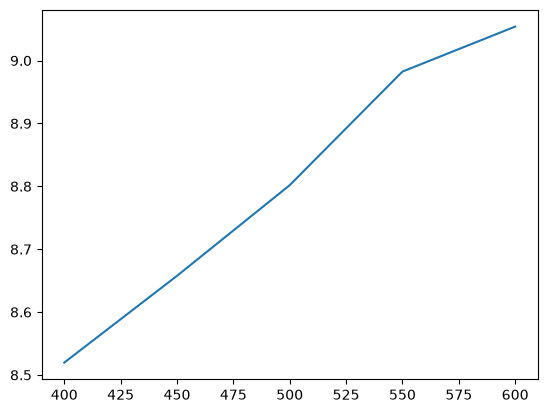

In [13]:
import matplotlib.pyplot as plt
plt.plot(df[df.pad_height_um == 100].pad_width_um, df[df.pad_height_um == 100].fQ)

In [7]:
df.plot(df[df['pad_height_um'] == 80]['pad_width_um'], df[df['pad_height_um']==80]['fQ'])

KeyError: "None of [Index([400.0, 450.0, 500.0, 550.0, 600.0], dtype='float64')] are in the [columns]"